# Notebook 03c — Embedder: DINOv2 (pretrained) + comparison

**Purpose:** embed FoodSeg103 food regions with pretrained DINOv2, evaluate with cosine KNN, and compare against
the from-scratch alternatives of notebooks 03a (HOG + colour) and 03b (miniature ViT).**.

---

## 1. What DINOv2 Does

DINOv2 (Oquab et al., Meta 2023) is a family of ViTs (ViT-S/14 21M, **ViT-B/14 86M → 768-dim**, ViT-L/14 300M,
ViT-g/14 1.1B) trained with **self-supervised learning** on 142M curated images. This notebook uses **ViT-B/14**.

Key idea: **DINO** (self-DIstillation with NO labels) trains a student network to match the output of a teacher
network (an exponential moving average of the student):

```
Image → [Augmentation A] → Student → CLS token
     → [Augmentation B] → Teacher → CLS token (target)
     Loss = cross-entropy(student, teacher)
```

After training, the CLS token is a rich embedding that captures **semantic similarity** — dishes that look alike
have embeddings close in cosine distance.

**Why we use it:** enrol once (store the embedding), then match at runtime by cosine similarity — no retraining.
That lookup **is** K-nearest-neighbours with K = 1, which is exactly how all three embedders are evaluated.

## Evaluation protocol (shared by notebooks 03a, 03b, 03c)

Every food-class region of a FoodSeg103 annotation with area ≥ 32×32 px becomes one sample:
bounding-box crop, background pixels zeroed, label = its FoodSeg103 class (103 classes).

- **Gallery** = all train-split regions ("enrolled" dishes), **queries** = test-split regions.
- Each query is matched to the gallery by **cosine similarity** (vectors are L2-normalised), exactly like the
  dish database lookup.
- Metrics (`foodseg_embed.knn_evaluate`): similarity-weighted **KNN accuracy** for K = 1, 3, 5, 10;
  **top-5 hit** (the right class is among the 5 nearest neighbours); **macro accuracy** (1-NN accuracy averaged over
  classes – FoodSeg103 is very imbalanced, so this is the fairer number).
- Results are written to `outputs/embed/<embedder>_test.json`; notebook 03c puts all of them in one table.

## 2. Library & configuration

In [1]:
import time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

import foodseg_common as fc
import foodseg_embed as fe

print(f'PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}')

PyTorch 2.10.0 | CUDA available: True


In [2]:
DINO_MODEL = 'dinov2_vitb14'   # dinov2_vits14 (384-d) / dinov2_vitb14 (768-d) / dinov2_vitl14 (1024-d)
CROP_SIZE  = 224               # multiple of the 14-px patch size
BATCH_SIZE = 64

TRAIN_LIMIT = None             # number of images (None = full split); e.g. 200 for a quick trial
TEST_LIMIT  = None

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NAMES = fe.category_names()
train_regions = fe.region_index('train', limit=TRAIN_LIMIT)
test_regions  = fe.region_index('test',  limit=TEST_LIMIT)
train_y, test_y = fe.labels_of(train_regions), fe.labels_of(test_regions)
print(f'gallery (train) regions: {len(train_regions)} | query (test) regions: {len(test_regions)} | device: {device}')

gallery (train) regions: 17982 | query (test) regions: 3887 | device: cuda


## 3. Load DINOv2

In [3]:
# The installed xformers build does not match this Python/PyTorch, so its attention kernels fail.
# DINOv2 reads this variable when its layers are imported and then uses PyTorch attention instead
# (if DINOv2 was already loaded in this kernel without it, restart the kernel).
import os
os.environ['XFORMERS_DISABLED'] = '1'

# Use the local torch.hub copy when available (no download), otherwise fetch from GitHub
HUB_REPO = Path(torch.hub.get_dir()) / 'facebookresearch_dinov2_main'
if HUB_REPO.exists():
    dino = torch.hub.load(str(HUB_REPO), DINO_MODEL, source='local')
else:
    dino = torch.hub.load('facebookresearch/dinov2', DINO_MODEL)
dino = dino.to(device).eval()

n_params = sum(p.numel() for p in dino.parameters())
EMBED_DIM = dino.embed_dim
print(f'{DINO_MODEL}: {n_params / 1e6:.1f}M parameters | embedding dim {EMBED_DIM}')

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

C:\Users\HPZ4G4Workstation\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
C:\Users\HPZ4G4Workstation\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\HPZ4G4Workstation\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
C:\Users\HPZ4G4Workstation\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\HPZ4G4Workstation\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:35: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (B

dinov2_vitb14: 86.6M parameters | embedding dim 768


## 4. Embed all regions

Each crop (224×224, background zeroed) → DINOv2 → CLS token (768-d), L2-normalised.
Embeddings are cached in `outputs/embed/` when the full split is used.

In [4]:
@torch.no_grad()
def dino_embed(batch_uint8):
    x = torch.as_tensor(np.stack(batch_uint8), device=device).permute(0, 3, 1, 2).float() / 255.0
    x = (x - MEAN) / STD
    with torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type == 'cuda'):
        out = dino(x)                    # CLS token after the final norm
    return fe.l2_normalise(out.float().cpu().numpy())


def embed_split(split, regions, limit):
    cache = fe.EMBED_ROOT / f'{DINO_MODEL}_{split}_s{CROP_SIZE}.npy' if limit is None else None
    if cache is not None and cache.exists():
        arr = np.load(cache)
        if len(arr) == len(regions):
            return arr, float('nan')
    feats = np.zeros((len(regions), EMBED_DIM), np.float32)
    batch, idx, t_model = [], [], 0.0
    def flush():
        nonlocal t_model
        t0 = time.time()
        feats[idx] = dino_embed(batch)
        t_model += time.time() - t0
        batch.clear(); idx.clear()
    for i, crop, _ in tqdm(fe.iter_crops(split, regions, CROP_SIZE), total=len(regions), desc=split):
        batch.append(crop); idx.append(i)
        if len(batch) == BATCH_SIZE:
            flush()
    if batch:
        flush()
    if cache is not None:
        np.save(cache, feats)
    return feats, t_model / max(len(regions), 1)


g_feats, _ = embed_split('train', train_regions, TRAIN_LIMIT)
q_feats, sec_per_crop = embed_split('test', test_regions, TEST_LIMIT)
print('gallery', g_feats.shape, '| queries', q_feats.shape,
      f'| model time {sec_per_crop * 1000:.2f} ms/crop' if not np.isnan(sec_per_crop) else '| (from cache)')

train:   0%|          | 0/17982 [00:00<?, ?it/s]

test:   0%|          | 0/3887 [00:00<?, ?it/s]

gallery (17982, 768) | queries (3887, 768) | model time 2.54 ms/crop


## 5. KNN evaluation on the test split

In [5]:
test_m, test_pc, test_pred = fe.knn_evaluate(g_feats, train_y, q_feats, test_y)
fe.save_result(DINO_MODEL, 'test', test_m,
               extra=dict(dim=EMBED_DIM, params=n_params, sec_per_crop=sec_per_crop,
                          crop_size=CROP_SIZE, notebook='03c'))
for k, v in test_m.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

  knn1_acc: 0.6671
  knn3_acc: 0.6851
  knn5_acc: 0.7059
  knn10_acc: 0.7113
  top5_hit: 0.8510
  macro_acc1: 0.5695
  n_gallery: 17982
  n_query: 3887


In [6]:
pc = pd.DataFrame(test_pc).T
pc['name'] = [NAMES[c_] for c_ in pc.index]
pc = pc[pc['n'] >= 10].sort_values('acc')
print('Hardest classes (n >= 10 test regions):'); print(pc.head(10)[['name', 'n', 'acc']].to_string())
print('\nEasiest classes:'); print(pc.tail(10)[['name', 'n', 'acc']].to_string())

Hardest classes (n >= 10 test regions):
                      name     n       acc
103      other ingredients  26.0  0.076923
98                shiitake  21.0  0.142857
51                    lamb  18.0  0.166667
47                    pork  86.0  0.244186
9            cheese butter  52.0  0.250000
50              fried meat  38.0  0.263158
81                 pumpkin  17.0  0.294118
28                 avocado  16.0  0.312500
54                    fish  58.0  0.327586
101  white button mushroom  25.0  0.360000

Easiest classes:
            name      n       acc
31        cherry   34.0  0.852941
88  celery stick   29.0  0.862069
32     blueberry   37.0  0.864865
66          rice   97.0  0.865979
65       noodles   45.0  0.888889
37         lemon   90.0  0.888889
95   green beans   28.0  0.928571
30    strawberry   90.0  0.933333
59          corn   84.0  0.940476
87      broccoli  140.0  0.950000


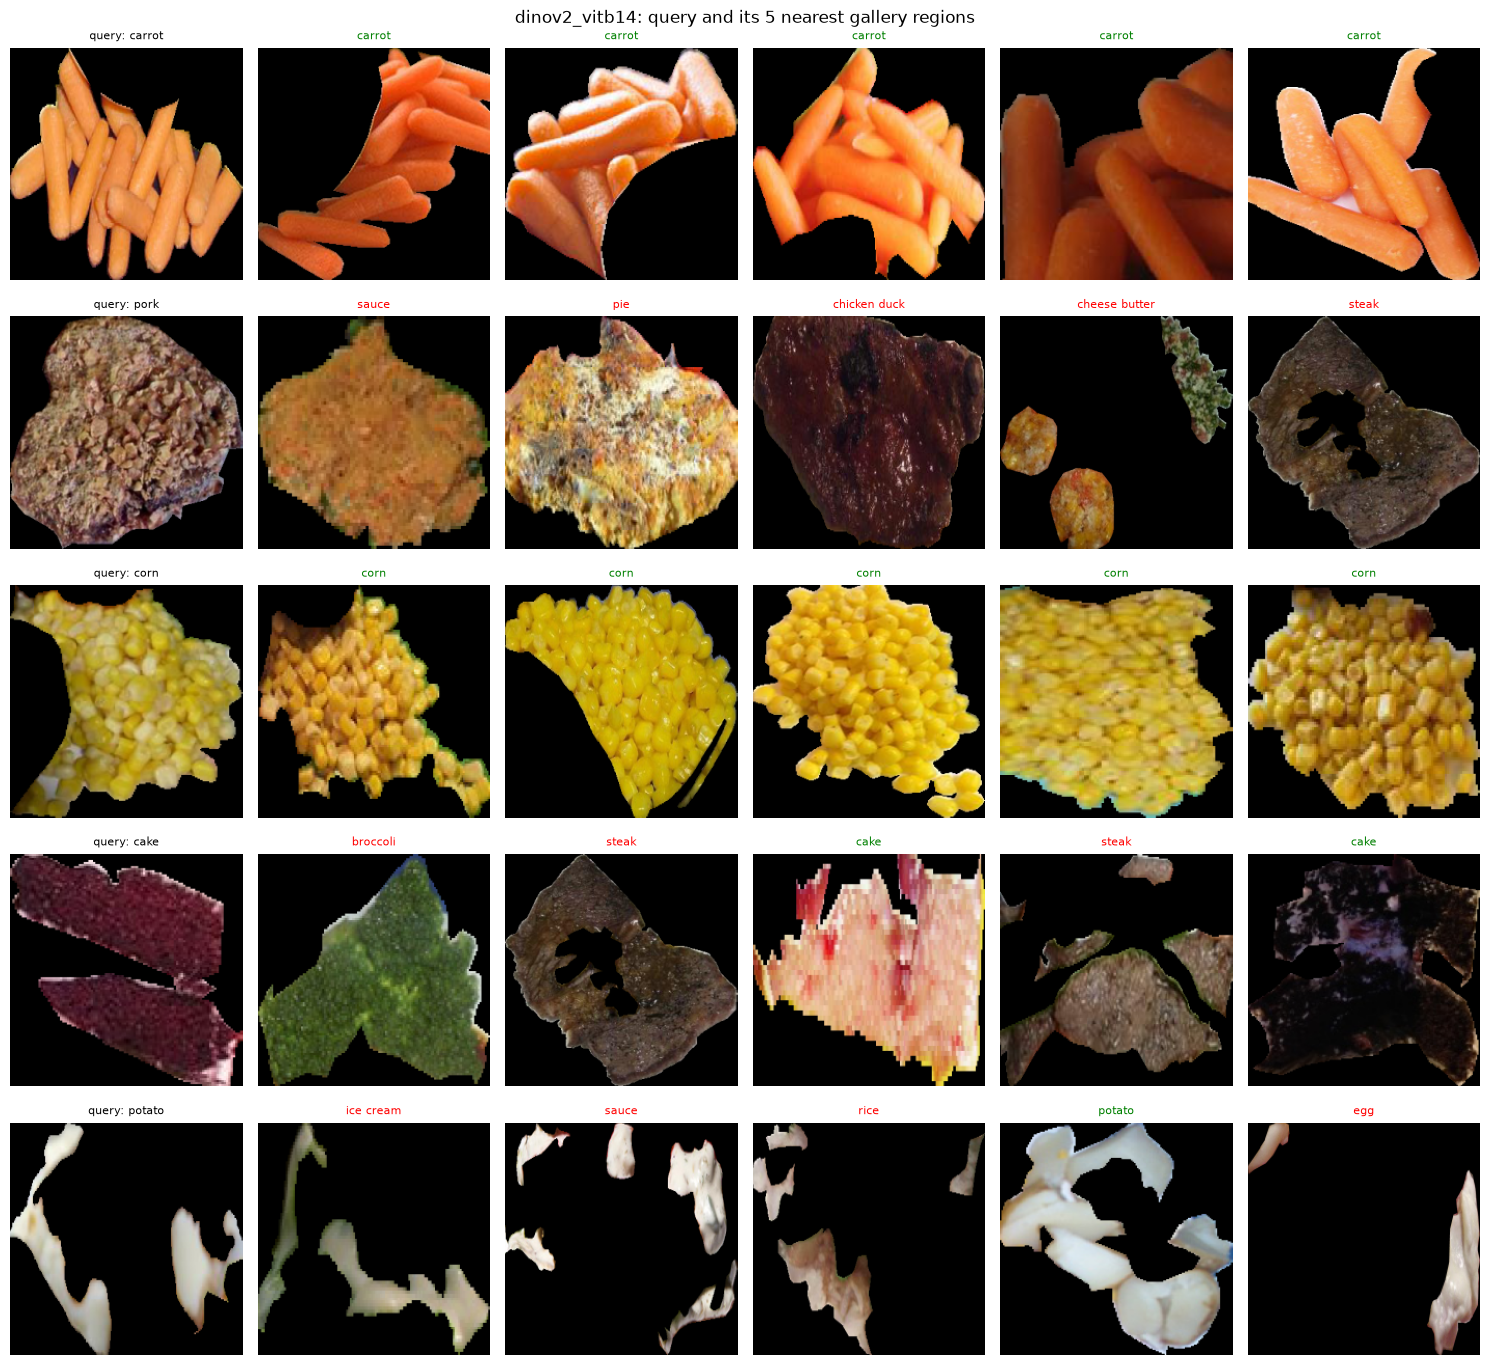

In [7]:
# Nearest-neighbour retrieval for a few test queries (green = same class as the query)
_, nn_idx = fe.knn_search(g_feats, q_feats, 5)
qs = np.random.default_rng(0).choice(len(test_regions), size=5, replace=False)
q_crops = [next(fe.iter_crops('test', [test_regions[i]], CROP_SIZE))[1] for i in qs]
g_crop = lambda j: next(fe.iter_crops('train', [train_regions[j]], CROP_SIZE))[1]
fig, axes = plt.subplots(len(qs), 6, figsize=(15, 2.8 * len(qs)))
fe.show_retrievals(axes, q_crops, test_y[qs], g_crop, nn_idx[qs], train_y, NAMES)
plt.suptitle(f'{DINO_MODEL}: query and its 5 nearest gallery regions', fontsize=12)
plt.tight_layout(); plt.show()

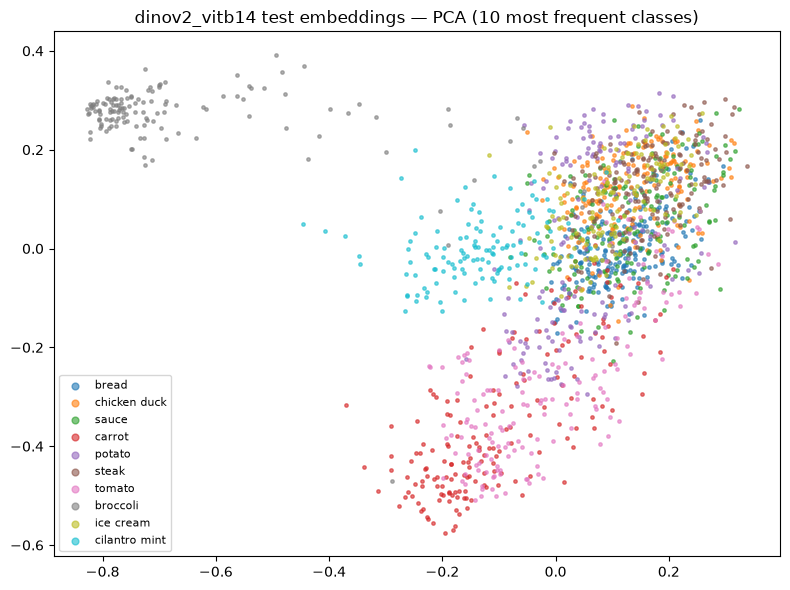

In [8]:
# 2-D PCA of the test embeddings for the 10 most frequent classes
top = pd.Series(test_y).value_counts().index[:10]
sel = np.isin(test_y, top)
xy = fe.pca_2d(q_feats[sel])
fig, ax = plt.subplots(figsize=(8, 6))
for c_ in top:
    m = test_y[sel] == c_
    ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.6, label=NAMES[c_])
ax.set_title(f'{DINO_MODEL} test embeddings — PCA (10 most frequent classes)'); ax.legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

## 6. Comparison: HOG + colour vs miniature ViT vs DINOv2

Reads every `outputs/embed/*_test.json` (written by 03a, 03b and this notebook). Run 03a and 03b first to fill
in their rows; missing ones are simply absent.

In [9]:
res = fe.load_results('test')
order = ['raw_pixels', 'colour_hist', 'hog', 'hog_colour', 'minivit_untrained', 'minivit', DINO_MODEL]
res = {k: res[k] for k in order if k in res} | {k: v for k, v in res.items() if k not in order}
cols = ['dim', 'params', 'knn1_acc', 'knn5_acc', 'top5_hit', 'macro_acc1', 'sec_per_crop', 'n_gallery', 'n_query']
comparison = pd.DataFrame(res).T.reindex(columns=cols)
comparison.to_csv(fe.EMBED_ROOT / 'comparison_test.csv')
print(comparison.to_string(float_format=lambda v: f'{v:.4f}'))

                    dim    params knn1_acc knn5_acc top5_hit macro_acc1 sec_per_crop n_gallery n_query
raw_pixels         3072       NaN   0.1160   0.1294   0.2930     0.0634       0.0007     17982    3887
colour_hist         512       NaN   0.1649   0.1986   0.4121     0.0843       0.0007     17982    3887
hog                1764       NaN   0.0944   0.1003   0.2490     0.0534       0.0007     17982    3887
hog_colour         2276       NaN   0.1685   0.1924   0.3872     0.0873       0.0007     17982    3887
minivit_untrained   128    824960   0.1479   0.1747   0.3959     0.0693          NaN     17982    3887
minivit             128    824960   0.2233   0.2634   0.4937     0.1273       0.0001     17982    3887
dinov2_vitb14       768  86580480   0.6671   0.7059   0.8510     0.5695       0.0025     17982    3887


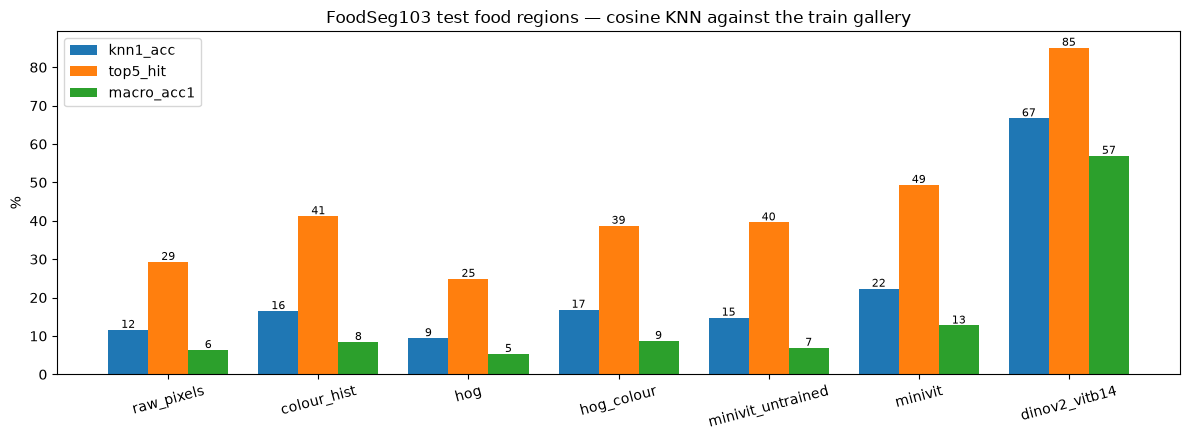

In [10]:
metrics = ['knn1_acc', 'top5_hit', 'macro_acc1']
fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.8 / len(metrics)
for k, met in enumerate(metrics):
    vals = comparison[met].astype(float).values * 100
    bars = ax.bar(np.arange(len(comparison)) + k * w, vals, w, label=met)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.5, f'{v:.0f}', ha='center', fontsize=8)
ax.set_xticks(np.arange(len(comparison)) + w * (len(metrics) - 1) / 2, comparison.index, rotation=15)
ax.set_ylabel('%'); ax.set_title('FoodSeg103 test food regions — cosine KNN against the train gallery'); ax.legend()
plt.tight_layout(); plt.savefig(fe.EMBED_ROOT / 'comparison_test.png', dpi=120); plt.show()

### Qualitative comparison

| Aspect | HOG + Histogram (03a) | Mini ViT from scratch (03b) | DINOv2 ViT-B/14 (03c) |
|---|---|---|---|
| Parameters | 0 (algorithm) | ≈0.8M | 86M |
| Training | None | Supervised on FoodSeg103 train regions | Self-supervised, 142M images |
| Output dim | 1,764 + 512 | 128 | 768 |
| Captures colour / shape / texture | explicit colour + gradients | learned | learned |
| Semantic understanding | None | Limited to the training classes | Strong |
| Explainability | High (each dim = gradient/colour bin) | Attention maps | Attention maps |
| GPU required | No | Helpful for training | Recommended |

> **The conclusion:** KNN is always the classifier — what changes is what you feed it. Measured accuracies are in
> the table above.